# Background

- **Author**: 待學生確認（已詢問姓名與實際負責工作；未將本次工作歸給既有作者）
- **Created At**: 2026-11-17
- **Research Motivation and Context (why are we interested in the findings?)**: 使用者指定合併所有現有州群，以 Python logistic regression 檢驗未控制收入、州別及貸款條件時，種族與房貸核准機率的關聯。觀測單位為申請紀錄，並非可識別的獨立申請人。輸入為 `data/processed/` 下的 [MA–CO–DC](../data/processed/state_MA-CO-DC_income_high_15_columns.csv)、[NM–LA–MS](../data/processed/state_NM-LA-MS_income_low_15_columns.csv)、[VT–ME–WV](../data/processed/state_VT-ME-WV_white_high_15_columns.csv)、[HI–DC–CA](../data/processed/state_HI-DC-CA_white_low_15_columns.csv)。來源說明與讀取核對見 [收入州群 Notebook](income_groups_mortgage_approval.ipynb) 及 [白人比例州群 Notebook](white_groups_mortgage_approval.ipynb)。資料年份及上游整理程式未確認；不推定為 2024 年，也不代表全美樣本。
- **Main Findings and Takeaways**: 已從乾淨 Jupyter kernel 實際執行；合併 10 州與 DC，N=1,068,027（DC 僅納入一次），核准結果平均 76.13%。白人、黑人、亞洲人核准機率依序為 77.60%、60.71%、77.95%。相對白人，黑人係數 −0.80720、OR=0.4461（95% CI 0.4399–0.4524，p<1e-300），亞洲人係數 0.02037、OR=1.0206（95% CI 1.0072–1.0342，p=0.002557）。黑人機率低 16.89 個百分點，亞洲人高 0.35 個百分點。整體 HC1 Wald χ²(2)=13259.874，p<1e-300。未控制其他條件的種族差異達統計顯著；亞洲人的差距幅度很小。上述結果為關聯，不能解讀為因果或歧視。
- **Future Direction**: 後續可在同一估計樣本加入收入、州別與貸款條件，比較種族係數變化；需先確認欄位定義、資料年份及缺失規則。

## 樣本與模型設定

合併 10 州與華盛頓特區（CA、CO、HI、LA、MA、ME、MS、NM、VT、WV、DC）。兩來源的 DC 先核對全部 15 欄資料列及重複列出現次數完全相同，才保留 MA–CO–DC 檔的一份；不對可能代表不同申請的其他相同資料列任意去重。合併只是同結構資料的縱向串接與重複來源 DC 篩選，沒有另建或覆寫資料檔。

核准 `Approved=1`：`action_taken` 為 1 或 2；拒絕 `Approved=0`：為 3；其餘結果不納入。種族只納入 White、Black or African American、Asian；白人為參考組。核准包含核准但未接受的申請，不等同實際撥款。收入及其他未使用條件缺失不影響本模型納入。

$$\operatorname{logit}\{P(Approved_i=1)\}=\beta_0+\beta_1Black_i+\beta_2Asian_i.$$

以最大概似估計，報告 HC1 異質變異穩健標準誤（sandwich covariance 乘以 $N/(N-3)$）。檢定黑人相對白人、亞洲人相對白人的雙尾 Wald p-value，以及 $H_0:\beta_1=\beta_2=0$ 的整體 Wald 檢定。這些為預先指定模型的未校正 p-value；星號：`* p < .10`、`** p < .05`、`*** p < .01`。未控制任何固定效果，不使用人口權重，不分訓練與測試集，因為目的是估計關聯。

HC1 仍假設紀錄間獨立，未調整州內、機構內或重複申請的相關性。州別可識別，但僅 11 個州／地區，且不是已確認的隨機群聚抽樣設計；本次以 HC1 作基礎分析，推論條件與限制明列，不將其當作已處理州群聚的結果。

In [1]:
# Load packages
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.special import expit
from scipy.stats import norm, chi2
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_white_simple
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
fonts={f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family']=next((f for f in ['Heiti TC','Arial Unicode MS','Noto Sans CJK TC'] if f in fonts),'DejaVu Sans')
plt.rcParams['axes.unicode_minus']=False
print({'Python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
       'scipy':scipy.__version__,'statsmodels':sm.__version__})


{'Python': '3.14.2', 'pandas': '3.1.1', 'numpy': '2.5.5', 'scipy': '1.18.1', 'statsmodels': '0.15.0'}


In [2]:
# Read exact verified prepared inputs; fail on changed bytes or schema.
start=Path.cwd().resolve()
ROOT=next((p for p in (start,*start.parents) if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()),None)
if ROOT is None: raise FileNotFoundError('請從專案根目錄或其子目錄執行。')
INPUTS={
 'state_MA-CO-DC_income_high_15_columns.csv':'bd7902271c1d3efa36bdd0d19d2f456753f4117db9a55fab9f434709ac904c8b',
 'state_NM-LA-MS_income_low_15_columns.csv':'e8ff73e6c26ce0189345feed4972863f3f91696249bc4a7c8fed37b0a0ccc7a4',
 'state_VT-ME-WV_white_high_15_columns.csv':'eb1f7f550eb397ead2f900c142f1521cb4da04a892111b494b9a9d8f2eabbf51',
 'state_HI-DC-CA_white_low_15_columns.csv':'7bc8724fa2db17f65d8a77bb91929be14ae8f063ede116317d24598e49ca1554'}
expected_states=[{'MA','CO','DC'},{'NM','LA','MS'},{'VT','ME','WV'},{'HI','DC','CA'}]
frames=[]
for (name,sha),states in zip(INPUTS.items(),expected_states):
    path=(ROOT/'data/processed'/name).resolve()
    assert path.is_relative_to((ROOT/'data/processed').resolve())
    assert hashlib.sha256(path.read_bytes()).hexdigest()==sha, f'輸入版本變更：{name}'
    frame=pd.read_csv(path,dtype=str)
    assert frame.shape[1]==15
    assert {'state_code','derived_race','action_taken'}<=set(frame)
    assert set(frame.state_code)==states
    frames.append(frame)
a=frames[0].loc[frames[0].state_code.eq('DC')]
b=frames[3].loc[frames[3].state_code.eq('DC')]
# Exact full-row multiset comparison, preserving duplicate multiplicities and missingness.
def row_multiset(frame):
    return frame.fillna('<MISSING>').value_counts(dropna=False).sort_index()
pd.testing.assert_series_equal(row_multiset(a),row_multiset(b))
assert len(a)==len(b)==8387
parts=[f.copy() for f in frames]
parts[3]=parts[3].loc[parts[3].state_code.ne('DC')].copy()
pooled=pd.concat(parts,ignore_index=True)
assert len(pooled)==1068027 and pooled.state_code.eq('DC').sum()==8387
assert pooled.state_code.nunique()==11
races=['White','Black or African American','Asian']
action=pd.to_numeric(pooled.action_taken,errors='coerce')
valid=action.isin([1,2,3]) & pooled.derived_race.isin(races)
analysis=pooled.loc[valid,['state_code','derived_race','action_taken']].copy()
analysis['Approved']=action.loc[valid].isin([1,2]).astype(int)
analysis['Black']=analysis.derived_race.eq(races[1]).astype(int)
analysis['Asian']=analysis.derived_race.eq(races[2]).astype(int)
assert not analysis.isna().any().any()
print('來源總筆數：',sum(map(len,frames)),'；排除重複來源 DC：',len(b))
print('合併 N：',len(pooled),'；模型有效 N：',len(analysis),'；結果或種族不符而排除：',int((~valid).sum()))
print('收入缺失不作為排除條件；來源沒有申請唯一鍵，不宣稱已辨識獨立申請人。')
display(analysis.head(10))


來源總筆數： 1076414 ；排除重複來源 DC： 8387
合併 N： 1068027 ；模型有效 N： 1068027 ；結果或種族不符而排除： 0
收入缺失不作為排除條件；來源沒有申請唯一鍵，不宣稱已辨識獨立申請人。


,state_code,derived_race,action_taken,Approved,Black,Asian
0,MA,Black or African American,1,1,1,0
1,CO,White,1,1,0,0
2,MA,Black or African American,3,0,1,0
3,MA,White,1,1,0,0
4,MA,White,2,1,0,0
5,CO,White,1,1,0,0
6,CO,White,1,1,0,0
7,MA,White,1,1,0,0
8,CO,White,1,1,0,0
9,CO,White,1,1,0,0


In [3]:
# Summary statistics BEFORE fitting: all model and sample-audit variables.
N=len(analysis)
print(f'表 1：模型數值變數摘要，估計樣本 N={N:,}；有效 N=count，缺失 N 另列')
labels={'Approved':'核准（1）／拒絕（0）','Black':'黑人指標','Asian':'亞洲人指標'}
stats=analysis[['Approved','Black','Asian']].describe().T.rename(index=labels)
stats['missing_N']=analysis[['Approved','Black','Asian']].isna().sum().to_numpy()
display(stats)
for col,title in [('derived_race','種族'),('action_taken','申請結果代碼'),('state_code','州／地區')]:
    counts=analysis[col].value_counts(dropna=True)
    print(f'表 2：{title}，有效 N={counts.sum():,}；缺失 N={analysis[col].isna().sum():,}；比例分母為非缺失筆數（州別全列 11 類）')
    display(pd.DataFrame({'筆數':counts,'比例（%）':counts/counts.sum()*100}))
print('Black 與 Asian 同時為 0 的申請皆為白人；沒有其他種族混入參考組。')
assert analysis.loc[analysis.Black.eq(0)&analysis.Asian.eq(0),'derived_race'].eq('White').all()


表 1：模型數值變數摘要，估計樣本 N=1,068,027；有效 N=count，缺失 N 另列


,count,mean,std,min,25%,50%,75%,max,missing_N
核准（1）／拒絕（0）,1068027.0,0.761308,0.426284,0.0,1.0,1.0,1.0,1.0,0
黑人指標,1068027.0,0.089984,0.286159,0.0,0.0,0.0,0.0,1.0,0
亞洲人指標,1068027.0,0.141075,0.348099,0.0,0.0,0.0,0.0,1.0,0


表 2：種族，有效 N=1,068,027；缺失 N=0；比例分母為非缺失筆數（州別全列 11 類）


,筆數,比例（%）
derived_race,,
White,821250,76.894123
Asian,150672,14.107509
Black or African American,96105,8.998368


表 2：申請結果代碼，有效 N=1,068,027；缺失 N=0；比例分母為非缺失筆數（州別全列 11 類）


,筆數,比例（%）
action_taken,,
1,766436,71.761856
3,254929,23.869153
2,46662,4.368991


表 2：州／地區，有效 N=1,068,027；缺失 N=0；比例分母為非缺失筆數（州別全列 11 類）


,筆數,比例（%）
state_code,,
CA,502455,47.045159
CO,151270,14.163500
MA,127860,11.971607
LA,79148,7.410674
MS,65543,6.136830
NM,37915,3.550004
ME,35186,3.294486
WV,33979,3.181474
HI,14146,1.324498


Black 與 Asian 同時為 0 的申請皆為白人；沒有其他種族混入參考組。


### The actual analysis starts below

模型不放入收入、州別或其他貸款條件。這個只有種族類別的模型對三種族各估計一個機率，因此其擬合核准率應等於各種族在模型樣本中的實際核准率；下列程式會核對此特性，也以封閉解核對係數與 HC1 covariance。

In [4]:
X=sm.add_constant(analysis[['Black','Asian']].astype(float))
y=analysis.Approved.astype(float)
fit=sm.Logit(y,X).fit(disp=False,maxiter=100)
assert fit.mle_retvals['converged']
# Explicit HC1 correction: avoid relying on version-specific HC1 naming behavior.
V=np.asarray(cov_white_simple(fit,use_correction=True))
beta=np.asarray(fit.params)
se=np.sqrt(np.diag(V))
zstat=beta/se
logp=np.log(2)+norm.logsf(np.abs(zstat))
pvalues=np.exp(logp)
z95=norm.ppf(.975)
lo,hi=beta-z95*se,beta+z95*se
race_counts=analysis.groupby('derived_race').Approved.agg(['sum','size','mean']).reindex(races)
assert race_counts['sum'].gt(0).all() and (race_counts['sum']<race_counts['size']).all()
logodds=np.log(race_counts['mean']/(1-race_counts['mean'])).to_numpy()
closed_beta=np.array([logodds[0],logodds[1]-logodds[0],logodds[2]-logodds[0]])
assert np.allclose(beta,closed_beta,atol=1e-9)
logit_var=1/race_counts['sum'].to_numpy()+1/(race_counts['size']-race_counts['sum']).to_numpy()
T=np.array([[1,0,0],[-1,1,0],[-1,0,1]])
closed_V=T@np.diag(logit_var)@T.T*N/(N-3)
assert np.allclose(V,closed_V,rtol=1e-8,atol=1e-12)
assert np.max(np.abs(X.to_numpy().T@(y.to_numpy()-fit.predict())))<1e-6

def p_text(p): return '<1e-300' if p<1e-300 else f'{p:.6g}'
def stars(p): return '***' if p<.01 else '**' if p<.05 else '*' if p<.10 else ''
coef=pd.DataFrame({'項目':['截距：白人 log-odds','黑人相對白人','亞洲人相對白人'],
 '係數':beta,'HC1標準誤':se,'z':zstat,'p_value':pvalues,'log10_p':logp/np.log(10),
 '係數CI95下限':lo,'係數CI95上限':hi,'勝算比OR':np.exp(beta),
 'OR_CI95下限':np.exp(lo),'OR_CI95上限':np.exp(hi)})
coef['p顯示']=coef.p_value.map(p_text)
coef['顯著性']=coef.p_value.map(stars)
print(f'表 3：僅種族 Logistic regression；N={N:,}；核准結果平均={y.mean():.4%}；HC1 標準誤；白人為參考組')
print('截距的 exp(係數) 是白人的基準勝算，不是組間勝算比。* p<.10；** p<.05；*** p<.01。')
display(coef.drop(columns=['p_value']).round(6))
# Joint robust Wald test, df=2. For df=2 the exact log survival is -W/2.
wald=float(beta[1:]@np.linalg.solve(V[1:,1:],beta[1:]))
joint_logp=-wald/2
joint_p=float(np.exp(joint_logp))
joint=pd.DataFrame([{'虛無假設':'Black = Asian = 0','Wald_chi2':wald,'df':2,
 'p_value':joint_p,'log10_p':joint_logp/np.log(10),'p顯示':p_text(joint_p)}])
print('表 4：種族係數整體 HC1 Wald 檢定；不是黑人與亞洲人彼此相等的檢定')
display(joint.drop(columns=['p_value']))
print('極小 p-value 以 <1e-300 顯示，log10_p 保留數值尺度；CSV 中的 0 為浮點下溢，不表示真實機率為零。')


表 3：僅種族 Logistic regression；N=1,068,027；核准結果平均=76.1308%；HC1 標準誤；白人為參考組
截距的 exp(係數) 是白人的基準勝算，不是組間勝算比。* p<.10；** p<.05；*** p<.01。


,項目,係數,HC1標準誤,z,log10_p,係數CI95下限,係數CI95上限,勝算比OR,OR_CI95下限,OR_CI95上限,p顯示,顯著性
0,截距：白人 log-odds,1.242541,0.002647,469.460064,-47860.447575,1.237354,1.247729,3.464407,3.446482,3.482425,<1e-300,***
1,黑人相對白人,-0.807200,0.007115,-113.442980,-2796.687956,-0.821146,-0.793254,0.446105,0.439927,0.452370,<1e-300,***
2,亞洲人相對白人,0.020375,0.006754,3.016492,-2.592238,0.007136,0.033613,1.020584,1.007162,1.034185,0.00255718,***


表 4：種族係數整體 HC1 Wald 檢定；不是黑人與亞洲人彼此相等的檢定


,虛無假設,Wald_chi2,df,log10_p,p顯示
0,Black = Asian = 0,13259.874075,2,-2879.345071,<1e-300


極小 p-value 以 <1e-300 顯示，log10_p 保留數值尺度；CSV 中的 0 為浮點下溢，不表示真實機率為零。


表 5：模型預測核准機率及 HC1 95% 區間，N=1,068,027；區間由 logit 尺度轉回機率


,種族,N,核准筆數,預測核准機率,機率CI95下限,機率CI95上限
0,白人,821250,637295,0.776006,0.775103,0.776906
1,黑人,96105,58350,0.607148,0.604056,0.610232
2,亞洲人,150672,117453,0.779528,0.777427,0.781614


表 6：相對白人的機率差異，95% 區間採 HC1 delta method；顯著性檢定見表 3 的 log-odds Wald 檢定


,比較,機率差（百分點）,差異CI95下限（百分點）,差異CI95上限（百分點）
0,黑人 − 白人,-16.885766,-17.207434,-16.564097
1,亞洲人 − 白人,0.352163,0.124241,0.580085


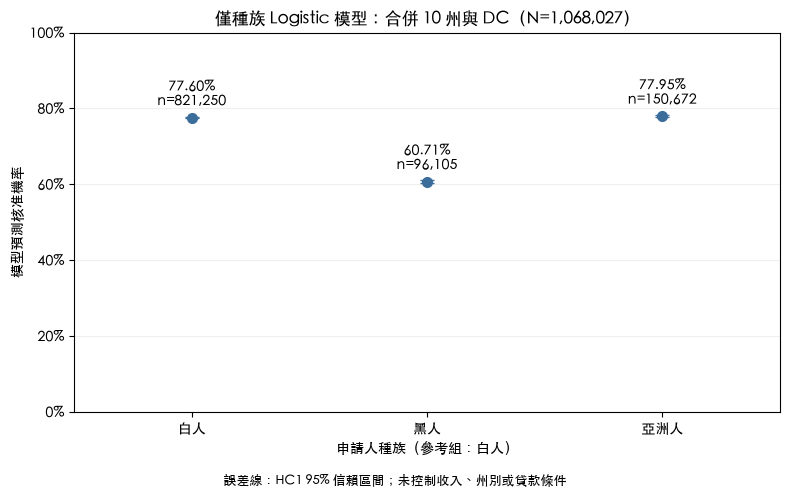

In [5]:
# Model probabilities and differences, using the same HC1 covariance.
profiles=np.array([[1,0,0],[1,1,0],[1,0,1]],dtype=float)
eta=profiles@beta
eta_se=np.sqrt(np.einsum('ij,jk,ik->i',profiles,V,profiles))
prob=expit(eta)
assert np.allclose(prob,race_counts['mean'].to_numpy(),atol=1e-10)
probability=pd.DataFrame({'種族':['白人','黑人','亞洲人'],'N':race_counts['size'].to_numpy(),
 '核准筆數':race_counts['sum'].to_numpy(),'預測核准機率':prob,
 '機率CI95下限':expit(eta-z95*eta_se),'機率CI95上限':expit(eta+z95*eta_se)})
grad=profiles*prob[:,None]*(1-prob[:,None])
diffs=[]
for j,label in [(1,'黑人 − 白人'),(2,'亞洲人 − 白人')]:
    g=grad[j]-grad[0]
    diff=float(prob[j]-prob[0])
    diff_se=float(np.sqrt(g@V@g))
    diffs.append({'比較':label,'機率差（百分點）':100*diff,
      '差異CI95下限（百分點）':100*(diff-z95*diff_se),
      '差異CI95上限（百分點）':100*(diff+z95*diff_se)})
difference=pd.DataFrame(diffs)
print(f'表 5：模型預測核准機率及 HC1 95% 區間，N={N:,}；區間由 logit 尺度轉回機率')
display(probability)
print('表 6：相對白人的機率差異，95% 區間採 HC1 delta method；顯著性檢定見表 3 的 log-odds Wald 檢定')
display(difference)
assets=ROOT/'finding/assets/pooled_race_logistic_regression'
assets.mkdir(parents=True,exist_ok=True)
outputs={'coefficients.csv':coef,'joint_test.csv':joint,'predicted_probabilities.csv':probability,
         'probability_differences.csv':difference}
for name,table in outputs.items():
    path=assets/name
    table.to_csv(path,index=False)
    reopened=pd.read_csv(path)
    assert reopened.shape==table.shape
    for col in table.select_dtypes(include='number'):
        assert np.allclose(reopened[col],table[col],rtol=1e-10,atol=1e-12)
metadata={'N':N,'outcome_mean':float(y.mean()),'states':sorted(analysis.state_code.unique()),
 'covariance':'HC1: sandwich * N/(N-3)','reference':'White','converged':bool(fit.mle_retvals['converged']),
 'inputs_sha256':INPUTS,'excluded_duplicate_source_DC':8387,'excluded_invalid_outcome_or_race':int((~valid).sum())}
(assets/'model_metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(8,5))
ax.errorbar(np.arange(3),prob,yerr=[prob-probability['機率CI95下限'].to_numpy(),probability['機率CI95上限'].to_numpy()-prob],
            fmt='o',capsize=5,color='#3b6d9b',markersize=7)
for j,p in enumerate(prob): ax.text(j,p+.025,f'{p:.2%}\nn={int(probability.iloc[j]["N"]):,}',ha='center',va='bottom')
ax.set_xticks(np.arange(3),probability['種族'])
ax.set_xlim(-.5,2.5)
ax.set_ylim(0,1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('申請人種族（參考組：白人）')
ax.set_ylabel('模型預測核准機率')
ax.set_title(f'僅種族 Logistic 模型：合併 10 州與 DC（N={N:,}）')
ax.grid(axis='y',alpha=.2)
fig.text(.5,.02,'誤差線：HC1 95% 信賴區間；未控制收入、州別或貸款條件',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1])
fig.savefig(assets/'predicted_probabilities.png',dpi=180,facecolor='white')
plt.show()
plt.close(fig)


In [6]:
findings=(f'合併 10 州與 DC，共 N={N:,}，核准比例 {y.mean():.2%}。'
 f'白人、黑人與亞洲人的預測核准機率依序為 {prob[0]:.2%}、{prob[1]:.2%}、{prob[2]:.2%}。'
 f'相對白人，黑人勝算比 {np.exp(beta[1]):.4f}（p={p_text(pvalues[1])}），'
 f'亞洲人勝算比 {np.exp(beta[2]):.4f}（p={p_text(pvalues[2])}）。'
 f'整體 Wald χ²(2)={wald:.3f}，p={p_text(joint_p)}。')
display(Markdown('### 實際結果與解讀\n\n'+findings+'\n\n'
 '本模型只有種族，所以預測機率等於各種族樣本核准率。勝算比比較的是 odds，不是機率倍數；'
 '機率差以表 6 的百分點呈現。若係數檢定顯著，代表此合併樣本中未調整的種族關聯存在統計證據，'
 '不能據此認定種族造成核准差異或認定歧視。\n\n'
 '來源為已選定州群，不代表全美；來源年份未確認；三種族之外無法推論。'
 '合併結果受各州及收入組成影響，HC1 未處理申請紀錄間的相關性。'
 '與前面的收入四分位圖不同，本模型保留收入缺失申請，因此不可直接把兩者差異當作模型加入控制後的變化。\n\n'
 '執行核對：乾淨 kernel 逐格完成；已驗證輸入 hash、DC 來源一致性、模型收斂、'
 '係數封閉解、HC1 covariance、預測率與原始核准率一致及四份 CSV 重新讀取。'
 '作者與貢獻歸屬待學生確認；尚待學生自行檢閱、commit 與 push。'))


### 實際結果與解讀

合併 10 州與 DC，共 N=1,068,027，核准比例 76.13%。白人、黑人與亞洲人的預測核准機率依序為 77.60%、60.71%、77.95%。相對白人，黑人勝算比 0.4461（p=<1e-300），亞洲人勝算比 1.0206（p=0.00255718）。整體 Wald χ²(2)=13259.874，p=<1e-300。

本模型只有種族，所以預測機率等於各種族樣本核准率。勝算比比較的是 odds，不是機率倍數；機率差以表 6 的百分點呈現。若係數檢定顯著，代表此合併樣本中未調整的種族關聯存在統計證據，不能據此認定種族造成核准差異或認定歧視。

來源為已選定州群，不代表全美；來源年份未確認；三種族之外無法推論。合併結果受各州及收入組成影響，HC1 未處理申請紀錄間的相關性。與前面的收入四分位圖不同，本模型保留收入缺失申請，因此不可直接把兩者差異當作模型加入控制後的變化。

執行核對：乾淨 kernel 逐格完成；已驗證輸入 hash、DC 來源一致性、模型收斂、係數封閉解、HC1 covariance、預測率與原始核准率一致及四份 CSV 重新讀取。作者與貢獻歸屬待學生確認；尚待學生自行檢閱、commit 與 push。